# GM12878 scNOMe-HiC (Hi-C part) vs sci-Hi-C — SCC calculation & figures

Compares the **Hi-C modality of the GM12878 scNOMe-HiC** pseudobulk to an independent
**GM12878 single-cell Hi-C (sci-Hi-C)** pseudobulk (Kim et al. 2020, `GM12878-IMR90.R1`,
489 GM12878 cells) using **HiCRep SCC at 2.5 Mb per chromosome** — the same metric as the
existing pseudobulk-vs-bulk comparison in `gm_sc_new/hic_comparison`.

This notebook **re-computes the SCC** from the per-chromosome 2.5 Mb contact dumps produced
by `code/run_pipeline.sbatch` (steps 01–04) and **generates all figures**:
1. SCC boxplots by percentile clip
2. per-chromosome SCC barplot (95th-pct clip)
3. side-by-side contact heatmaps (scNOMe-HiC vs sci-Hi-C)
4. matched-bin contact scatter (Spearman/Pearson)

**Kernel:** `scnomehic` (hicrep + cooler 0.10.3). If the 2.5 Mb dumps are missing, run
`sbatch code/run_pipeline.sbatch` first.

In [1]:
# --- environment ---------------------------------------------------------------
# This notebook was written against the `scnomehic` conda environment.
#     conda env create -f env/scnomehic.yml && conda activate scnomehic
# See env/README.md for which notebook uses which environment.
_ENV_EXPECTED = "scnomehic"
import os as _os, sys as _sys
if _os.path.basename(_sys.prefix) != _ENV_EXPECTED:
    print(f"[env] expected the '{_ENV_EXPECTED}' environment, running in "
          f"'{_os.path.basename(_sys.prefix)}' ({_sys.prefix}). See env/README.md.",
          file=_sys.stderr)

# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has chdir'd away.
import os as _os, sys as _sys
if "REPO_ROOT" not in globals():
    _r = _os.getcwd()
    while _r != "/" and not _os.path.exists(_os.path.join(_r, "paths.py")):
        _r = _os.path.dirname(_r)
    assert _os.path.exists(_os.path.join(_r, "paths.py")), \
        "paths.py not found above the working directory -- start Jupyter inside the repository"
    REPO_ROOT = _r
_sys.path.insert(0, REPO_ROOT)
from paths import DATA, REFERENCE, SOFTWARE, WORK, TMP, CONDA_SH, CONDA_ENVS

import os, re, warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.stats import spearmanr, pearsonr
import cooler
from hicrep import hicrepSCC
from hicrep.utils import readMcool
warnings.filterwarnings("ignore")

ROOT = WORK + "/analysis/s2_new/schic_gm12878"
DUMP = f"{ROOT}/work/dump_2.5Mb"
COOL = f"{ROOT}/work/cool_files"; os.makedirs(COOL, exist_ok=True)
FIG  = f"{ROOT}/figures"; os.makedirs(FIG, exist_ok=True)

BIN_SIZE = 2_500_000
H        = 3
IS_LOG   = False
CHROMS   = [f"chr{i}" for i in range(1, 23)] + ["chrX"]
PCTS     = [95, 99, 100]

path_nome  = lambda c: f"{DUMP}/nomehic_2.5Mb_{c}.txt"
path_schic = lambda c: f"{DUMP}/schic_gm_2.5Mb_{c}.txt"
assert os.path.exists(path_nome("chr1")) and os.path.exists(path_schic("chr1")), \
    "2.5 Mb dumps missing — run `sbatch code/run_pipeline.sbatch` first."
print("dumps found in", DUMP)

dumps found in /gpfs/projects/b1198/epifluidlab/yoshii/scnomehic_paper/s2_new/schic_gm12878/work/dump_2.5Mb


## 1. Load the 2.5 Mb contact matrices

In [2]:
def load_matrix(path, bin_size=BIN_SIZE):
    """Juicer-style triplet dump (start1 start2 count) -> dense symmetric matrix."""
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        return np.zeros((0, 0))
    df = pd.read_csv(path, sep="\t", header=None, names=["s1", "s2", "c"])
    if df.empty:
        return np.zeros((0, 0))
    b1 = (df.s1 // bin_size).astype(int); b2 = (df.s2 // bin_size).astype(int)
    n = int(max(b1.max(), b2.max()) + 1)
    m = np.zeros((n, n))
    for i, j, v in zip(b1, b2, df.c):
        m[i, j] = v; m[j, i] = v
    return m

nome = {c: load_matrix(path_nome(c))  for c in CHROMS}
schic= {c: load_matrix(path_schic(c)) for c in CHROMS}

summary = pd.DataFrame({
    "chrom": CHROMS,
    "nome_bins":  [nome[c].shape[0]  for c in CHROMS],
    "schic_bins": [schic[c].shape[0] for c in CHROMS],
    "nome_contacts":  [int(np.triu(nome[c]).sum())  for c in CHROMS],
    "schic_contacts": [int(np.triu(schic[c]).sum()) for c in CHROMS],
})
print("total scNOMe-HiC contacts:", summary.nome_contacts.sum(),
      " | total sci-Hi-C contacts:", summary.schic_contacts.sum())
summary

total scNOMe-HiC contacts: 252644916  | total sci-Hi-C contacts: 3474568


,chrom,nome_bins,schic_bins,nome_contacts,schic_contacts
0,chr1,100,100,20476796,301086
1,chr2,97,97,21049712,295798
2,chr3,80,80,17531022,242977
3,chr4,77,76,15301878,200370
4,chr5,73,73,15493014,210375
5,chr6,69,69,14732962,196914
6,chr7,64,64,13531709,178668
7,chr8,59,59,12544871,173436
8,chr9,56,56,10438727,135325
9,chr10,54,54,12167614,168637


## 2. HiCRep SCC calculation

For each chromosome and percentile cap: align both maps to a common bin count, clip raw
counts at the percentile, write single-chromosome `.cool` files, and call
`hicrepSCC(nomehic, schic, H=3, 2.5 Mb, is_log=False, [chrom])`. SCC is symmetric in its
two inputs.

In [3]:
def clip_vmax(m, pct):
    return 1.0 if m.size == 0 else float(np.percentile(m.ravel(), pct))

def save_cool(m, chrom, out):
    n = m.shape[0]
    if n == 0:
        return False
    bins = pd.DataFrame({"chrom": [chrom]*n,
                         "start": np.arange(0, n*BIN_SIZE, BIN_SIZE, dtype=np.int64),
                         "end":   np.arange(BIN_SIZE, (n+1)*BIN_SIZE, BIN_SIZE, dtype=np.int64)})
    iu, ju = np.triu_indices(n); cnt = m[iu, ju].astype(np.float64); keep = cnt > 0
    px = pd.DataFrame({"bin1_id": iu[keep].astype(np.int64),
                       "bin2_id": ju[keep].astype(np.int64), "count": cnt[keep]})
    if os.path.exists(out):
        os.remove(out)
    cooler.create_cooler(out, bins=bins, pixels=px, dtypes={"count": "float64"},
                         ordered=True, symmetric_upper=True)
    return True

rows = []
for pct in PCTS:
    for c in CHROMS:
        mn, ms = nome[c], schic[c]
        if mn.size == 0 or ms.size == 0:
            continue
        n = min(mn.shape[0], ms.shape[0]); mn, ms = mn[:n, :n], ms[:n, :n]
        cn = f"{COOL}/nomehic_{c}_{pct}.cool"; cs = f"{COOL}/schic_{c}_{pct}.cool"
        save_cool(np.minimum(mn, clip_vmax(mn, pct)), c, cn)
        save_cool(np.minimum(ms, clip_vmax(ms, pct)), c, cs)
        try:
            nc, _ = readMcool(cn, -1); sc, _ = readMcool(cs, -1)
            v = float(np.asarray(hicrepSCC(nc, sc, H, BIN_SIZE, IS_LOG, np.array([c]))).ravel()[0])
            rows.append({"percentile": pct, "chrom": c, "SCC": v})
        except Exception as e:
            print("ERR", c, pct, e)

def ck(c):
    m = re.match(r"chr(\d+)$", c); return (0, int(m.group(1))) if m else (1, 23)
scc = pd.DataFrame(rows).sort_values(["percentile", "chrom"],
                                     key=lambda s: s.map(ck) if s.name == "chrom" else s)
scc.to_csv(f"{FIG}/schic_scc_by_chrom_and_percentile.csv", index=False)
print("SCC summary by percentile clip:")
scc.groupby("percentile")["SCC"].agg(["mean", "median", "min", "max", "count"]).round(3)

SCC summary by percentile clip:


,mean,median,min,max,count
percentile,,,,,
95,0.897,0.948,0.594,0.999,23
99,0.666,0.782,-0.178,0.988,23
100,0.661,0.754,-0.178,0.988,23


## 3. Figure 1 — SCC boxplots by percentile clip

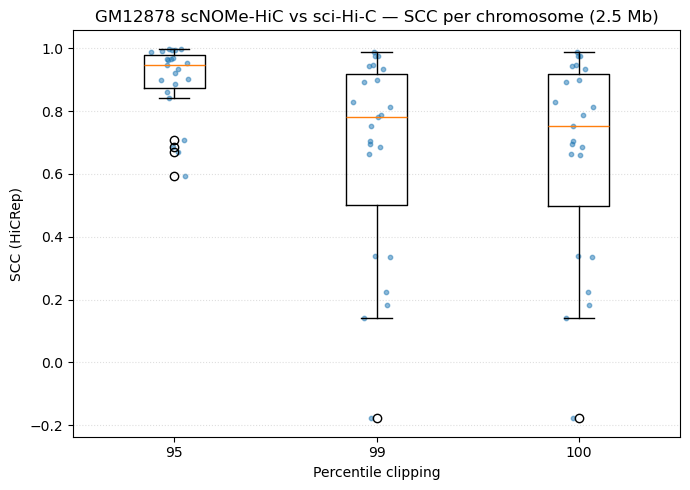

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot([scc.loc[scc.percentile == p, "SCC"].dropna().values for p in PCTS],
           labels=[str(p) for p in PCTS], showfliers=True)
for k, p in enumerate(PCTS, 1):
    y = scc.loc[scc.percentile == p, "SCC"].values
    ax.scatter(np.random.default_rng(0).normal(k, 0.05, len(y)), y, s=10, alpha=.5, color="tab:blue")
ax.set_xlabel("Percentile clipping"); ax.set_ylabel("SCC (HiCRep)")
ax.set_title("GM12878 scNOMe-HiC vs sci-Hi-C — SCC per chromosome (2.5 Mb)")
ax.grid(axis="y", ls=":", alpha=.4); fig.tight_layout()
fig.savefig(f"{FIG}/schic_scc_boxplots_by_percentile.png", dpi=300)
fig.savefig(f"{FIG}/schic_scc_boxplots_by_percentile.pdf"); plt.show()

## 4. Figure 2 — per-chromosome SCC (95th-percentile clip)

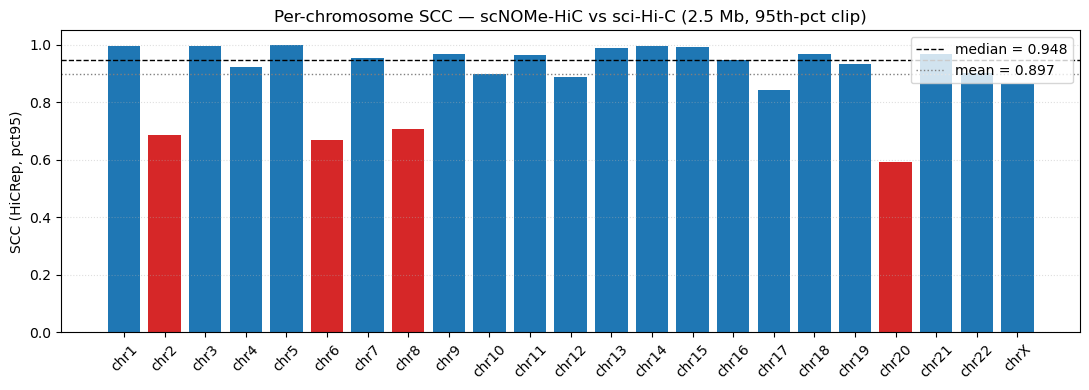

In [5]:
d = scc[scc.percentile == 95].copy()
fig, ax = plt.subplots(figsize=(11, 4))
colors = ["tab:red" if v < 0.75 else "tab:blue" for v in d.SCC]
ax.bar(d.chrom, d.SCC, color=colors)
ax.axhline(d.SCC.median(), ls="--", color="k", lw=1,
           label=f"median = {d.SCC.median():.3f}")
ax.axhline(d.SCC.mean(), ls=":", color="grey", lw=1, label=f"mean = {d.SCC.mean():.3f}")
ax.set_ylim(0, 1.05); ax.set_ylabel("SCC (HiCRep, pct95)")
ax.set_title("Per-chromosome SCC — scNOMe-HiC vs sci-Hi-C (2.5 Mb, 95th-pct clip)")
ax.legend(); ax.grid(axis="y", ls=":", alpha=.4)
plt.xticks(rotation=45); fig.tight_layout()
fig.savefig(f"{FIG}/schic_scc_by_chrom_bar.png", dpi=300)
fig.savefig(f"{FIG}/schic_scc_by_chrom_bar.pdf"); plt.show()

## 5. Figure 3 — example contact-matrix heatmaps

Side-by-side log-scale 2.5 Mb contact maps for a few chromosomes, with the per-chromosome
SCC annotated. The distance-decay and large-scale structure should visibly agree.

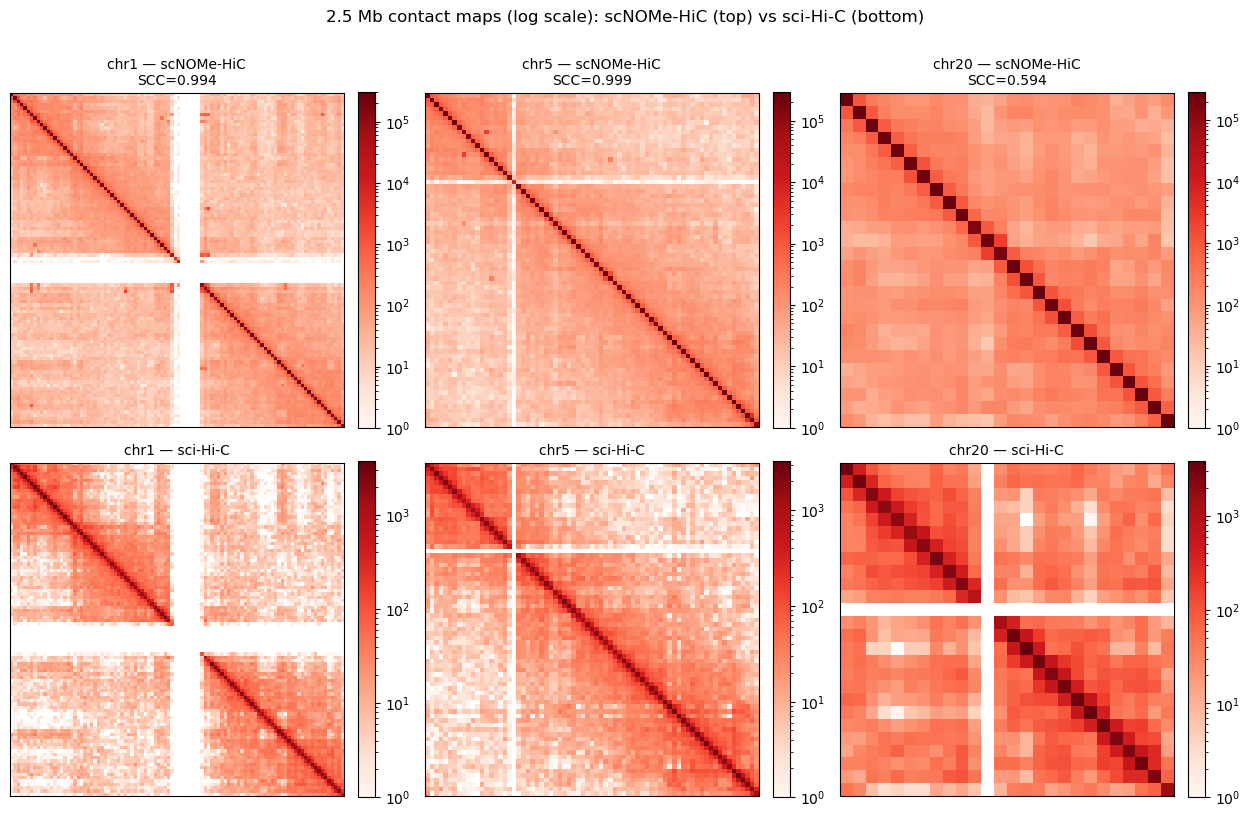

In [6]:
show_chroms = ["chr1", "chr5", "chr20"]   # high, high, low-SCC examples
fig, axes = plt.subplots(2, len(show_chroms), figsize=(4.2*len(show_chroms), 8))
s95 = scc[scc.percentile == 95].set_index("chrom")["SCC"]
for j, c in enumerate(show_chroms):
    n = min(nome[c].shape[0], schic[c].shape[0])
    for i, (mat, name) in enumerate([(nome[c], "scNOMe-HiC"), (schic[c], "sci-Hi-C")]):
        m = mat[:n, :n].copy(); m[m == 0] = np.nan
        ax = axes[i, j]
        im = ax.imshow(m, cmap="Reds", norm=LogNorm(vmin=1, vmax=np.nanmax(m)))
        ax.set_title(f"{c} — {name}" + (f"\nSCC={s95[c]:.3f}" if i == 0 else ""), fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=.046, pad=.04)
fig.suptitle("2.5 Mb contact maps (log scale): scNOMe-HiC (top) vs sci-Hi-C (bottom)", y=1.01)
fig.tight_layout()
fig.savefig(f"{FIG}/schic_example_heatmaps.png", dpi=200)
fig.savefig(f"{FIG}/schic_example_heatmaps.pdf"); plt.show()

## 6. Figure 4 — matched-bin contact scatter

Pool all intra-chromosomal off-diagonal 2.5 Mb bin pairs across chromosomes and compare the
raw contact counts of the two assays (bins present in either map). Spearman is the natural
statistic (rank concordance of contact frequency).

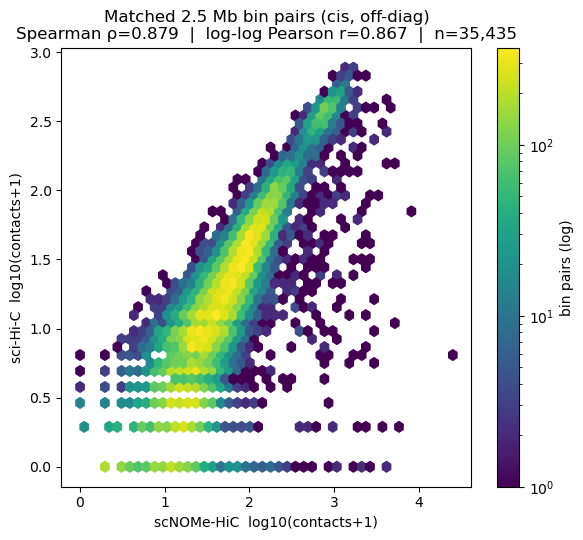

Spearman rho = 0.8793 ; log-log Pearson r = 0.8668 ; n bin-pairs = 35,435


In [7]:
xs, ys = [], []
for c in CHROMS:
    n = min(nome[c].shape[0], schic[c].shape[0])
    if n == 0:
        continue
    a = nome[c][:n, :n]; b = schic[c][:n, :n]
    iu, ju = np.triu_indices(n, k=1)
    x = a[iu, ju]; y = b[iu, ju]
    keep = (x + y) > 0
    xs.append(x[keep]); ys.append(y[keep])
x = np.concatenate(xs); y = np.concatenate(ys)
rho, _ = spearmanr(x, y)
r, _   = pearsonr(np.log1p(x), np.log1p(y))

fig, ax = plt.subplots(figsize=(6, 5.5))
hb = ax.hexbin(np.log10(x + 1), np.log10(y + 1), gridsize=45, bins="log", cmap="viridis", mincnt=1)
ax.set_xlabel("scNOMe-HiC  log10(contacts+1)"); ax.set_ylabel("sci-Hi-C  log10(contacts+1)")
ax.set_title(f"Matched 2.5 Mb bin pairs (cis, off-diag)\nSpearman ρ={rho:.3f}  |  log-log Pearson r={r:.3f}  |  n={len(x):,}")
fig.colorbar(hb, ax=ax, label="bin pairs (log)")
fig.tight_layout()
fig.savefig(f"{FIG}/schic_matched_bin_scatter.png", dpi=300)
fig.savefig(f"{FIG}/schic_matched_bin_scatter.pdf"); plt.show()
print(f"Spearman rho = {rho:.4f} ; log-log Pearson r = {r:.4f} ; n bin-pairs = {len(x):,}")

## 7. Figure 5 — SCC by resolution (500 kb / 1 Mb / 2.5 Mb)

Reproduces the resolution series of `gm_sc_new/hic_comparison` (`gm_scc_rawclip_by_resolution`)
for the sci-Hi-C comparison. **Only 500 kb, 1 Mb, 2.5 Mb are possible**: the sci-Hi-C source is
processed at **500 kb**, so it can only be aggregated coarser — **250 kb / 100 kb are NOT
achievable** without re-binning read-level data (the 4DN raw FASTQ). scNOMe-HiC is dumped from
its `.hic` at each resolution; sci-Hi-C is re-binned from the lifted 500 kb contacts. SCC uses
the 95th-percentile ("rawclip") cap, HiCRep H=3. Shown as a **violin plot** styled to match the
reference figure (`snakemake/hic_comparison_gm_clean.ipynb`, cell 17: light-blue bodies, red
median line, extrema hidden, y-axis 0–1).

In [8]:
RESOLUTIONS = {"500kb": 500_000, "1Mb": 1_000_000, "2.5Mb": 2_500_000}
MULTI = f"{ROOT}/work/dump_multires"
assert os.path.exists(f"{MULTI}/nomehic_500kb_chr1.txt"), \
    "multires dumps missing — run `sbatch code/run_multires.sbatch` first."

def save_cool_res(m, chrom, res, out):
    n = m.shape[0]
    if n == 0:
        return False
    bins = pd.DataFrame({"chrom": [chrom]*n,
                         "start": np.arange(0, n*res, res, dtype=np.int64),
                         "end":   np.arange(res, (n+1)*res, res, dtype=np.int64)})
    iu, ju = np.triu_indices(n); cnt = m[iu, ju].astype(np.float64); keep = cnt > 0
    px = pd.DataFrame({"bin1_id": iu[keep].astype(np.int64),
                       "bin2_id": ju[keep].astype(np.int64), "count": cnt[keep]})
    if os.path.exists(out):
        os.remove(out)
    cooler.create_cooler(out, bins=bins, pixels=px, dtypes={"count": "float64"},
                         ordered=True, symmetric_upper=True)
    return True

res_rows = []
for lab, res in RESOLUTIONS.items():
    for c in CHROMS:
        mn = load_matrix(f"{MULTI}/nomehic_{lab}_{c}.txt",  bin_size=res)
        ms = load_matrix(f"{MULTI}/schic_gm_{lab}_{c}.txt", bin_size=res)
        if mn.size == 0 or ms.size == 0:
            continue
        n = min(mn.shape[0], ms.shape[0]); mn, ms = mn[:n, :n], ms[:n, :n]
        cn = f"{COOL}/nome_{c}_{lab}.cool"; cs = f"{COOL}/schic_{c}_{lab}.cool"
        save_cool_res(np.minimum(mn, clip_vmax(mn, 95)), c, res, cn)
        save_cool_res(np.minimum(ms, clip_vmax(ms, 95)), c, res, cs)
        try:
            nc, _ = readMcool(cn, -1); sc, _ = readMcool(cs, -1)
            v = float(np.asarray(hicrepSCC(nc, sc, H, res, IS_LOG, np.array([c]))).ravel()[0])
            res_rows.append({"bin_size": lab, "chrom": c, "SCC": v})
        except Exception as e:
            print("ERR", lab, c, e)

res_df = pd.DataFrame(res_rows)
res_df.to_csv(f"{FIG}/schic_scc_rawclip_by_resolution.csv", index=False)
print("SCC by resolution (95th-pct clip):")
res_df.groupby("bin_size")["SCC"].agg(["mean", "median", "min", "count"]).reindex(RESOLUTIONS).round(3)

SCC by resolution (95th-pct clip):


,mean,median,min,count
bin_size,,,,
500kb,0.861,0.902,0.490,23
1Mb,0.903,0.954,0.493,23
2.5Mb,0.897,0.948,0.594,23


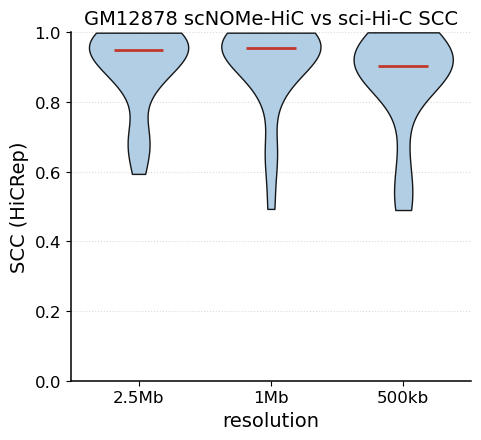

2.5Mb: median=0.948 mean=0.897 n=23
1Mb: median=0.954 mean=0.903 n=23
500kb: median=0.902 mean=0.861 n=23


In [9]:
import matplotlib as mpl
# Violin plot styled to match gm_sc_new/hic_comparison's gm_scc_rawclip_by_resolution.pdf
# (its notebook snakemake/hic_comparison_gm_clean.ipynb, cell 17). That reference used
# 1Mb/500kb/250kb and excluded chr4; here we use the achievable 2.5Mb/1Mb/500kb (sci-Hi-C
# source is 500 kb -> no 250 kb) and keep all chromosomes (chr4 is not an outlier here).
order = ["2.5Mb", "1Mb", "500kb"]                       # coarse -> fine, as in the reference
data  = [res_df.loc[res_df.bin_size == r, "SCC"].dropna().values for r in order]

with mpl.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.family": "sans-serif",
                     "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
                     "font.size": 13, "axes.titlesize": 14, "axes.labelsize": 14,
                     "xtick.labelsize": 12, "ytick.labelsize": 12, "axes.linewidth": 1.1,
                     "savefig.dpi": 300, "savefig.bbox": "tight"}):
    pos = np.arange(1, len(order) + 1)
    fig, ax = plt.subplots(figsize=(5.0, 4.6))
    parts = ax.violinplot(data, positions=pos, widths=0.75,
                          showmedians=True, showextrema=False)
    for b in parts["bodies"]:
        b.set_facecolor("#aac9e3"); b.set_edgecolor("black")
        b.set_alpha(0.9); b.set_linewidth(1.0)
    parts["cmedians"].set_color("#c0392b"); parts["cmedians"].set_linewidth(2.0)
    ax.set_xticks(pos); ax.set_xticklabels(order)
    ax.set_ylim(0, 1.0)
    ax.set_ylabel("SCC (HiCRep)"); ax.set_xlabel("resolution")
    ax.set_title("GM12878 scNOMe-HiC vs sci-Hi-C SCC")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True); ax.yaxis.grid(True, ls=":", alpha=0.45)
    fig.tight_layout()
    fig.savefig(f"{FIG}/schic_scc_rawclip_by_resolution.pdf")
    fig.savefig(f"{FIG}/schic_scc_rawclip_by_resolution.png", dpi=300)
    plt.show()
for r, d in zip(order, data):
    print(f"{r}: median={np.median(d):.3f} mean={np.mean(d):.3f} n={len(d)}")

## 8. Summary

At the standard **95th-percentile clip**, GM12878 scNOMe-HiC and sci-Hi-C are highly
concordant at 2.5 Mb (see the boxplot / barplot medians above) — validating the Hi-C
modality of scNOMe-HiC against an independent single-cell Hi-C dataset. The 99/100-pct
(little/no clip) values are noise-dominated by a few extreme bins in the sparse map, so the
95th-pct SCC is the honest metric (as in the existing pseudobulk-vs-bulk run).

**SCC by resolution:** the 500 kb / 1 Mb / 2.5 Mb series (section 7) mirrors the
`gm_scc_rawclip_by_resolution` panel from the existing bulk comparison. 250 kb is not
shown because the sci-Hi-C source is only processed at 500 kb.

All figures saved to `figures/`:
`schic_scc_boxplots_by_percentile`, `schic_scc_by_chrom_bar`, `schic_example_heatmaps`,
`schic_matched_bin_scatter`, `schic_scc_rawclip_by_resolution` (each `.png` + `.pdf`), and the
tables `schic_scc_by_chrom_and_percentile.csv`, `schic_scc_rawclip_by_resolution.csv`.